In [59]:
pip install numpy scipy matplotlib pandas scipy


^C
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
print("Hello Quant Finance")

Hello Quant Finance


In [1]:
import math

In [18]:
def crr_call_price(S0,K,r,sigma,T,N):
    dt= T/N
    u= math.exp(sigma*math.sqrt(dt))
    d= 1/u
    p = (math.exp(r * dt) - d) / (u - d)

    #maturity stock prices
    stock_prices = []
    for j in range(N + 1):

        stock_price = S0 * (u ** j) * (d ** (N - j))

        stock_prices.append(stock_price)

    #compute payoffs max(S-K,0)
    payoffs= []
    for S in stock_prices:
        payoff= max(S-K,0)
        payoffs.append(payoff)
    print(payoffs)

    #option pricing
    new_values=[]
    for i in range(len(payoffs)-1):
        value= math.exp(-r*dt)*(p*payoffs[i+1]+(1-p)*payoffs[i])
        new_values.append(value)
    print(new_values)

    #backward induction
    while len(payoffs) > 1:
        new_values = []

        for i in range(len(payoffs) - 1):

            value = math.exp(-r * dt) * (
                p * payoffs[i + 1]
                + (1 - p) * payoffs[i]
            )

            new_values.append(value)

        payoffs = new_values
    return payoffs[0]
    




    
    

In [1]:
pip install ipykernel

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
price = crr_call_price(100,100,0.05,0.2,1,100)
print(price)


[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1.4210854715202004e-13, 4.081077419238952, 8.328706767495987, 12.749685157937705, 17.35108709918113, 22.140275816017123, 27.124915032140578, 32.31298123374381, 37.71277643359582, 43.33294145603412, 49.18246976412712, 55.27072185113366, 61.6074402192894, 68.20276496988868, 75.06725002961014, 82.21188003905093, 89.64808793049511, 97.38777322304472, 105.44332106438875, 113.82762204968179, 122.55409284924667, 131.63669767810904, 141.0899706417208, 150.92903899362958, 161.16964734231152, 171.82818284590434, 182.92170143515568, 194.46795510655204, 206.48542032929987, 218.99332761161804, 232.01169227365426, 245.56134647626703, 259.66397255692755, 274.3421377260856, 289.6193301795207, 305.5199966844666, 322.0695816996544, 339.2945680918748, 357.2225195142149, 375.8821245137843, 395.30324243951037, 415.5169512234668, 436.5555971121961, 458.452846

In [21]:
#For varying N (time steps)
for N in [1,5,25,50,100,1000]:
    price = crr_call_price(
        100,100,0.05,0.2,1,N
    )

    print(N, price)

[0, 22.14027581601698]
[12.162284964623943]
1 12.162284964623943
[0, 0, 0, 9.356469114854164, 30.777622592251873, 56.39483159353719]
[0.0, 0.0, 4.944430799632212, 20.583389997763717, 44.008807084319656]
5 10.805933920410084
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 4.081077419238753, 12.749685157937492, 22.14027581601691, 32.31298123374361, 43.33294145603395, 55.270721851133516, 68.20276496988853, 82.21188003905081, 97.38777322304466, 113.82762204968176, 131.63669767810907, 150.9290389936297, 171.8281828459044]
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 2.0976357076513006, 8.528506900762483, 17.55088723244765, 27.3247151654071, 37.912576566862334, 49.38226989739365, 61.80724035255595, 75.26705016287673, 89.84788806376174, 105.64312119765538, 122.75389298251336, 141.2897707749876, 161.36944747557837]
25 10.520965623983946
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 5.819914392398346, 11.978542820145293, 18.49559815013305, 25.39194052123

In [6]:
import math

def norm_cdf(x):
    return 0.5 * (1 + math.erf(x / math.sqrt(2)))


In [7]:
#Implement Black Scholes
import math

def bs_call_price(S0, K, r, sigma, T):

    d1 = (
        math.log(S0 / K)
        + (r + 0.5 * sigma**2) * T
    ) / (sigma * math.sqrt(T))

    d2 = d1 - sigma * math.sqrt(T)

    call = (
        S0 * norm_cdf(d1)
        - K * math.exp(-r * T) * norm_cdf(d2)
    )

    return call

In [19]:
#Convergence
bs = bs_call_price(100,100,0.05,0.2,1)

print("BS =", bs)

for N in [1,2,3,5,10,25,50,100,500,100]:

    crr = crr_call_price(
        100,100,0.05,0.2,1,N)

    print("CRR=", crr)

BS = 10.450583572185565
[0, 22.14027581601698]
[12.162284964623943]
CRR= 12.162284964623943
[0, 0.0, 32.68964411453439]
[0.0, 17.65999981405763]
CRR= 9.540501338582947
[0, 0, 12.240090244566758, 41.398245808051655]
[0.0, 6.545862681454761, 27.631233198923148]
CRR= 11.043871091951113
[0, 0, 0, 9.356469114854164, 30.777622592251873, 56.39483159353719]
[0.0, 0.0, 4.944430799632212, 20.583389997763717, 44.008807084319656]
CRR= 10.805933920410084
[0, 0, 0, 0, 0, 0, 13.483935833151634, 28.78603692182878, 46.15146350242716, 65.85843306030654, 88.22267774802904]
[0.0, 0.0, 0.0, 0.0, 0.0, 7.02759129019261, 21.39187161299759, 37.69302227742363, 56.19220963750628, 77.18581555087698]
CRR= 10.25340904487193
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 4.081077419238753, 12.749685157937492, 22.14027581601691, 32.31298123374361, 43.33294145603395, 55.270721851133516, 68.20276496988853, 82.21188003905081, 97.38777322304466, 113.82762204968176, 131.63669767810907, 150.9290389936297, 171.8281828459044]
[0.0,

[0, 22.14027581601698]
[12.162284964623943]
[0, 0.0, 32.68964411453439]
[0.0, 17.65999981405763]
[0, 0, 12.240090244566758, 41.398245808051655]
[0.0, 6.545862681454761, 27.631233198923148]
[0, 0, 0.0, 22.14027581601701, 49.18246976412709]
[0.0, 0.0, 11.759311758176635, 36.22810070821222]
[0, 0, 0, 9.356469114854164, 30.777622592251873, 56.39483159353719]
[0.0, 0.0, 4.944430799632212, 20.583389997763717, 44.008807084319656]
[0, 0, 0, 1.4210854715202004e-14, 17.73890485513961, 38.624497164876146, 63.21496482286918]
[0.0, 0.0, 7.480330194388973e-15, 9.33743031383935, 28.585483067966237, 51.24792958661475]
[0, 0, 0, 0, 7.852341206763157, 25.45521844982619, 45.93110970229591, 69.74892748252225]
[0.0, 0.0, 0.0, 4.120272071003004, 17.03301579470562, 36.0181310211016, 58.10185911984105]
[0, 0, 0, 0, 0, 15.190991016890877, 32.68964411453436, 52.84651603231774, 76.06541655241782]
[0.0, 0.0, 0.0, 0.0, 7.950116963379721, 24.254161922039273, 43.034952885758635, 64.66873211767766]
[0, 0, 0, 0, 0, 6.

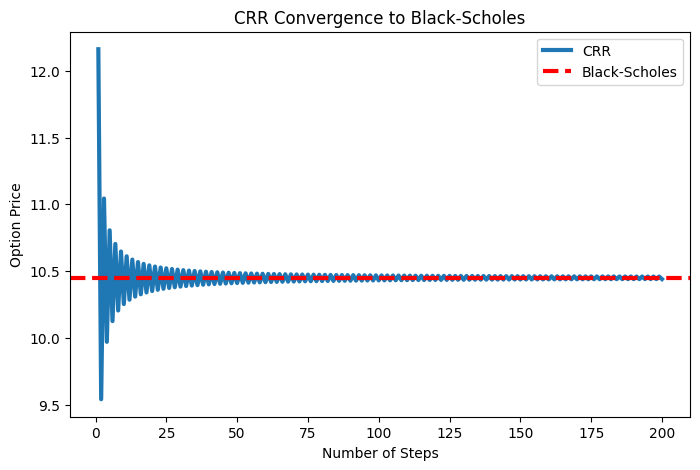

In [27]:
import matplotlib.pyplot as plt

steps = []
prices = []

for N in range(1,201):
    prices.append(
        crr_call_price(100,100,0.05,0.2,1,N)
    )
    steps.append(N)

bs = bs_call_price(100,100,0.05,0.2,1)

plt.figure(figsize=(8,5))

plt.plot(
    steps,
    prices,
    linewidth=3,
    label="CRR"
)

plt.axhline(color="red",
    y=bs,
    linestyle="--",
    linewidth=3,
    label="Black-Scholes"
)
plt.xlabel("Number of Steps")
plt.ylabel("Option Price")
plt.title("CRR Convergence to Black-Scholes")

plt.legend()

plt.show()

